In [1]:
import numpy as np 
import matplotlib.pyplot as plt


In [2]:
# basic statistics
x = np.array([1,2,3,4]) # array
mx = np.mean(x) # mean
dx = x - mx # deviation
var = np.mean(dx*dx) # variance
std = np.sqrt(var) # standard deviation

x, mx, dx, var, std

(array([1, 2, 3, 4]),
 2.5,
 array([-1.5, -0.5,  0.5,  1.5]),
 1.25,
 1.118033988749895)

In [3]:
y = [4,3,2,1]
my = np.mean(y)
dy = y - my

y, my, dy

([4, 3, 2, 1], 2.5, array([ 1.5,  0.5, -0.5, -1.5]))

In [4]:
deviation_products = dx*dy
covariance = np.mean(dx*dy)
deviation_products, covariance

(array([-2.25, -0.25, -0.25, -2.25]), -1.25)

In [5]:
# divide deviations by standard deviation
zx = dx/np.std(x) # covariance of normalized deviation, or "correlation"
x, np.std(x), zx

(array([1, 2, 3, 4]),
 1.118033988749895,
 array([-1.34164079, -0.4472136 ,  0.4472136 ,  1.34164079]))

In [6]:
zy = dy/np.std(y)
y, np.std(y), zy

([4, 3, 2, 1],
 1.118033988749895,
 array([ 1.34164079,  0.4472136 , -0.4472136 , -1.34164079]))

In [7]:
# mean of the normalize deviation: correlation
# is this Pearson's coefficient of correlation?
correlation = np.mean(zx * zy)
correlation

-1.0

In [8]:
# correlation:
#1- make the mean zero: dx = x -> (x - mean(x))
#2- make the standard deviation 1: zx = x-mean(x) -> (x-mean(x))/std(x) = dx/std(x)
#3- now kiss! correlation = np.mean(dx * dy)
zx, zy, zx*zy, np.mean(zx*zy)

(array([-1.34164079, -0.4472136 ,  0.4472136 ,  1.34164079]),
 array([ 1.34164079,  0.4472136 , -0.4472136 , -1.34164079]),
 array([-1.8, -0.2, -0.2, -1.8]),
 -1.0)

In [9]:
# proving it's true
for _ in range(5):
    xx = np.random.randint(1,10, 5)
    mxx = np.mean(xx)
    dxx = xx - mxx
    stdxx = np.std(xx)
    nxx = dxx/stdxx
    print(
        xx,round(np.mean(xx),2), 
        round(np.std(xx),2), 
        round(np.mean(dxx),2), 
        round(np.std(dxx),2),        
        round(np.std(nxx),2)
    )

[2 8 5 4 2] 4.2 2.23 -0.0 2.23 1.0
[7 4 2 4 8] 5.0 2.19 0.0 2.19 1.0
[8 6 4 5 2] 5.0 2.0 0.0 2.0 1.0
[6 7 8 6 6] 6.6 0.8 0.0 0.8 1.0
[9 2 2 2 4] 3.8 2.71 0.0 2.71 1.0


In [10]:
# different ways to calculate correlation
varx = np.mean(dx*dx)
stdx = np.sqrt(varx)
vary = np.mean(dy*dy)
stdy = np.sqrt(vary)
covxy = np.mean(dx*dy)
varx, vary, stdx, stdy, covxy


(1.25, 1.25, 1.118033988749895, 1.118033988749895, -1.25)

In [11]:
zx = dx/stdx
zy = dy/stdy
corr = np.mean(zx*zy)
zx,zy, corr

(array([-1.34164079, -0.4472136 ,  0.4472136 ,  1.34164079]),
 array([ 1.34164079,  0.4472136 , -0.4472136 , -1.34164079]),
 -1.0)

In [12]:
# petals

from sklearn.datasets import load_iris

data = load_iris(as_frame = True)
df = data.frame
dic = {x:y for x,y in zip(range(3), data.target_names)}
df['target'] = df['target'].map(dic)
for target, table in df.groupby('target'):
    globals()[target+'_pl'] = table['petal length (cm)']
    globals()[target+'_pw'] = table['petal width (cm)']

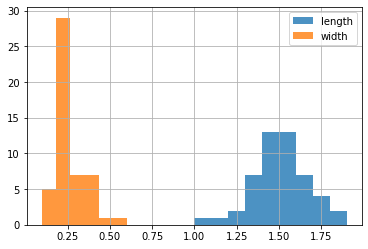

In [13]:
# difference of data and normalizations: no normalization
bins_pl = len(set(setosa_pl))
bins_pw = len(set(setosa_pw))
plt.hist(setosa_pl, bins = bins_pl, label = 'length', alpha = 0.8)
plt.hist(setosa_pw, bins = bins_pw, label = 'width', alpha = 0.8)
plt.grid()
plt.legend()
plt.show()

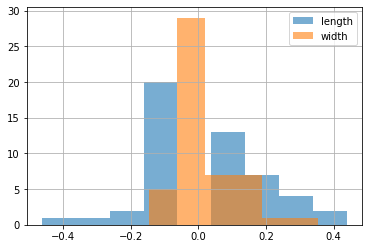

In [14]:
# normalized for mean:
d_setosa_pl = setosa_pl - np.mean(setosa_pl)
d_setosa_pw = setosa_pw - np.mean(setosa_pw)
plt.hist(d_setosa_pl, bins = bins_pl, label = 'length', alpha = 0.6)
plt.hist(d_setosa_pw, bins = bins_pw, label = 'width', alpha = 0.6)
plt.grid()
plt.legend()
plt.show()

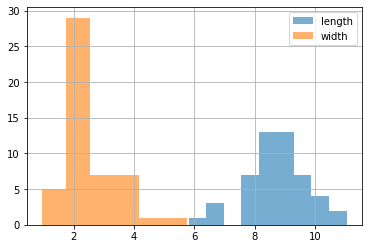

In [15]:
# normalized for standard deviation:
s_setosa_pl = setosa_pl/np.std(setosa_pl)
s_setosa_pw = setosa_pw/np.std(setosa_pw)
plt.hist(s_setosa_pl, bins = bins_pl, label = 'length', alpha = 0.6)
plt.hist(s_setosa_pw, bins = bins_pw, label = 'width', alpha = 0.6)
plt.grid()
plt.legend()
plt.show()

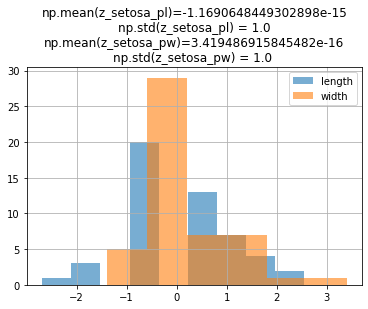

In [16]:
# normalized for mean and standard deviation:
z_setosa_pl = (setosa_pl - np.mean(setosa_pl)) /np.std(setosa_pl)
z_setosa_pw = (setosa_pw - np.mean(setosa_pw))/np.std(setosa_pw)
plt.hist(z_setosa_pl, bins = bins_pl, label = 'length', alpha = 0.6)
plt.hist(z_setosa_pw, bins = bins_pw, label = 'width', alpha = 0.6)
plt.grid()
plt.legend()
plt.title(f'{np.mean(z_setosa_pl)=}\n{np.std(z_setosa_pl) = }\n{np.mean(z_setosa_pw)=}\n{np.std(z_setosa_pw) = } ')
plt.show()

In [17]:
np.mean(z_setosa_pl * z_setosa_pw), np.corrcoef(setosa_pl, setosa_pw)[0,1]

(0.33163004080411873, 0.3316300408041187)

In [18]:
np.mean(d_setosa_pl * d_setosa_pw)

0.005948000000000001

In [19]:
np.cov(setosa_pl, setosa_pw, ddof = 0)

array([[0.029556, 0.005948],
       [0.005948, 0.010884]])

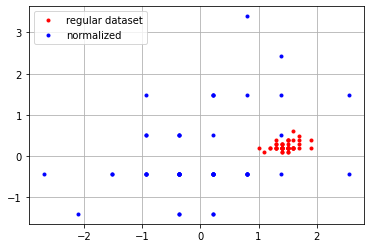

In [20]:
plt.plot(setosa_pl, setosa_pw, ' .r', label ='regular dataset')
plt.plot(z_setosa_pl, z_setosa_pw, ' .b', label = 'normalized')
plt.legend()
plt.grid()

In [21]:
# taylor... series? wtf
def model(x, a0=3, a1=2, a2=1):
    return a0 + a1*x + a2*x*x

x = np.linspace(-10,10,21)
y = model(x)

x

array([-10.,  -9.,  -8.,  -7.,  -6.,  -5.,  -4.,  -3.,  -2.,  -1.,   0.,
         1.,   2.,   3.,   4.,   5.,   6.,   7.,   8.,   9.,  10.])

In [22]:
y

array([ 83.,  66.,  51.,  38.,  27.,  18.,  11.,   6.,   3.,   2.,   3.,
         6.,  11.,  18.,  27.,  38.,  51.,  66.,  83., 102., 123.])

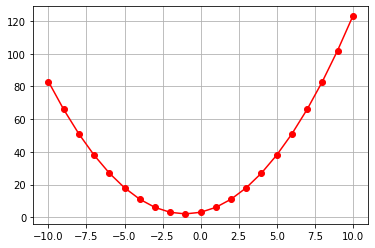

In [23]:
plt.plot(x,y, '-or')
plt.grid()

In [24]:
import pandas as pd
from statsmodels.formula.api import ols

In [25]:
dfx = pd.DataFrame({
    'lala':[1,2,3],
    'lele':[20,30,40]
})

dfx

,lala,lele
0,1,20
1,2,30
2,3,40


In [26]:
lala = ols(formula = 'lala ~lele', data = dfx)

In [27]:
lala2 =lala.fit()

In [28]:
interc = lala2.params['Intercept']
slope = lala2.params['lele']
slope, interc

(0.09999999999999998, -0.9999999999999986)

In [29]:
dfx['lele']*slope + interc

0    1.0
1    2.0
2    3.0
Name: lele, dtype: float64

In [30]:
import numpy as np 

def model(data, a0, a1):
    return a0 + data*a1

data = np.array([1,2,3,4,5])

model(data, 10,1)

array([11, 12, 13, 14, 15])

In [31]:
dic = {'a1':1, 'a0':10}
model(data, **dic)

array([11, 12, 13, 14, 15])

In [32]:
dic = {'a0':10, 'a1':1}
model(data, **dic)

array([11, 12, 13, 14, 15])

In [33]:
lala = [10,1]
model(data, *lala)

array([11, 12, 13, 14, 15])

In [34]:
# finding slope and intercept
a1 = np.cov(setosa_pl, setosa_pw, ddof = 0)[0,1]/np.var(setosa_pl)
a0 = np.mean(setosa_pw) - a1*np.mean(setosa_pl)
a0,a1

(-0.04822032751387209, 0.201245094058736)

In [35]:
np.polyfit(setosa_pl, setosa_pw, deg = 1)

array([ 0.20124509, -0.04822033])

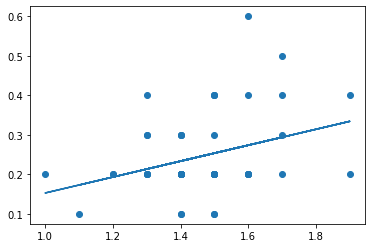

In [36]:
plt.scatter(setosa_pl, setosa_pw)
ys = a0 + setosa_pl*a1
plt.plot(setosa_pl, ys)

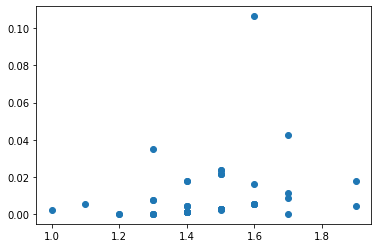

In [37]:
#plotting just residuals
plt.scatter(setosa_pl, (setosa_pw - ys)**2)


In [38]:
# statsmodels 

from statsmodels.formula.api import ols 

df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [39]:
dfs = pd.DataFrame(
    {
        'setosa_pl':setosa_pl,
        'setosa_pw':setosa_pw
    })
model_fit = ols(formula = 'setosa_pw ~ setosa_pl', data = dfs).fit()
model_fit.params

Intercept   -0.048220
setosa_pl    0.201245
dtype: float64

<AxesSubplot:xlabel='setosa_pl'>

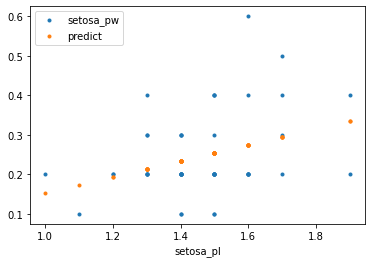

In [40]:
dfs['predict'] = model_fit.predict(dfs)
dfs.set_index('setosa_pl').plot(linestyle = '', marker = '.')

In [41]:
from scipy import optimize

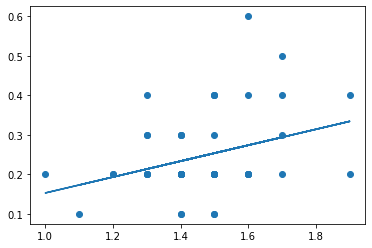

In [42]:
def lala(x, a0, a1):
    return a0 + a1*x

a,b = optimize.curve_fit(lala, setosa_pl, setosa_pw)
intercept, slope = a
intercept, slope

plt.scatter(setosa_pl, setosa_pw)
plt.plot(setosa_pl, intercept + setosa_pl*slope)

In [43]:
# calculating slope manually
np.sum((setosa_pl - np.mean(setosa_pl))*(setosa_pw - np.mean(setosa_pw)))/np.sum((setosa_pl-np.mean(setosa_pl))**2)

0.20124509405873603

[[0.20124509]] [-0.04822033]
[[0.20124509]] [-0.04822033]


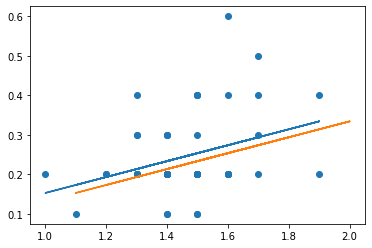

In [44]:
from sklearn.linear_model import LinearRegression
model0 = LinearRegression(fit_intercept = True)
model1 = LinearRegression(fit_intercept = True)

setosa_x = setosa_pl.values.reshape(len(setosa_pl),1)
setosa_y = setosa_pw.values.reshape(len(setosa_pw),1)

model0.fit(setosa_x, setosa_y)
model1.fit(setosa_x, setosa_y)

print(model0.coef_, model0.intercept_)
print(model1.coef_, model1.intercept_)

predict0 = model0.predict(setosa_x)
predict1 = model1.predict(setosa_x)
y0 = np.concatenate(predict0)
y1 = np.concatenate(predict1)

plt.scatter(setosa_pl, setosa_pw)
plt.plot(setosa_pl, y0)
plt.plot(setosa_pl + 0.1, y1)

In [45]:
a1 = np.cov(setosa_pl, setosa_pw, ddof = 0)[0,1]/np.var(setosa_pl)
a0 = np.mean(setosa_pw) - a1*np.mean(setosa_pl)
a0,a1

(-0.04822032751387209, 0.201245094058736)

In [46]:
# Setosa: residual, mean squared error, root mean squared error
# MSE, RMSE
residuals = setosa_pw - (setosa_pl * a1 + a0)
deviations = np.mean(setosa_pw) - setosa_pw
rss = np.sum(np.square(residuals))
mse = np.mean(rss)
rmse = np.sqrt(mse)
np.mean(np.square(residuals)), np.mean(np.square(deviations)), np.mean(np.square(residuals))/ np.mean(np.square(deviations))

(0.009686994180538639, 0.010883999999999998, 0.8900215160362588)

In [ ]:
rss/np.var(setosa_pl)

### Goodness of fit
3 different R:  
- RSS  
- RMSE  
- R-squared  

```python
residuals = y_model - y_data
RSS = np.sum(np.square(residuals)) # Residuals Squared Sum
MSE = np.sum(np.square(residuals))/len(residuals)
MSE = np.mean(np.square(residuals)) # Mean Squared Residuals
RMSE = np.sqrt(np.mean(np.square(residuals)))
RMSE = np.sqrt(MSE)
RMSE = np.sqrt(np.mean(RSS))
RMSE = np.std(residuals)
```

Deviations:
```python
deviations = np.mean(y_data) - y_data # difference between data y_value and data mean
VAR = np.sum(np.square(deviations))/len(deviations) # Mean Squared Deviation
```

Residuals:
```python
residuals = y_model - y_data
MSE = np.sum(np.square(residuals))/len(residuals)
```

R-squared:
```python
r_squared = 1 - (RSS / VAR)
r_squared = 1 - (  np.sum(np.square(residuals))/np.sum(np.square(deviations)) )
r_squared = 1 - ( np.sum(np.square(y_model - y_data))/np.sum(np.square(y_data - np.mean(y_data)))  )
r = correlation(y_data, y_model)
```